# TN3K · U-Net 3+ · Colab eğitimi

1. **İlk oturum.** Colab’da Tesla T4 seç. Aşağıdaki ayarlarda `EPOCHS_THIS_SESSION = 1` kalsın ve hücreleri yukarıdan aşağıya çalıştır. Kısa GPU denemesinden sonra 1. epoch tamamlanır ve Drive’a kaydedilir.
2. **Devam kontrolü.** İlk oturum başarıyla kaydettikten sonra yeni bir T4 oturumu aç ve aynı ayarlarla yeniden çalıştır. Eğitim başlamadan **Son tamamlanan epoch: 1 / Başlanacak epoch: 2** satırını görmelisin.
3. **Uzun eğitim.** Devam kontrolünden sonra yalnız `EPOCHS_THIS_SESSION` değerini artır. Aynı deney adını koru ve aynı deney klasörünü tek bir oturumdan çalıştır.

Ana Drive bağlıysa varsayılan manifest yolu hazır. Başka bir Google hesabı kullanıyorsan doğrulanmış `verified_split_manifest.csv` dosyasını o Drive’a kopyala ve `MANIFEST_PATH` alanına yeni tam yolu yaz. `DATASET_ROOT` boşken TN3K v2 otomatik hazırlanır. Bir hücre durursa başlığını ve hata mesajını paylaş.

## 1 · Drive, Tesla T4 ve ayarlar

Deney klasörünü ve oturum sınırını seçer, GPU’yu doğrular. Kaynak notebook’taki eğitim ayarları korunur. Her oturumda çalışacak epoch sayısı ayrı tutulur.

In [31]:
EXPERIMENT_NAME = "Colab_T4_Sifirdan_01"
DATASET_ROOT = ""  # İsteğe bağlı. Dört TN3K veri klasörünü içeren yerel dizin.
MANIFEST_PATH = "/content/drive/MyDrive/TN3K/verified_split_manifest.csv"
EPOCHS_THIS_SESSION = 89
TOTAL_EPOCHS = 100  # Kaynak deneydeki üst sınır. İlk kayıt sonrası sabit kalır.

import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

from pathlib import Path
from google.colab import drive
import torch

drive.mount("/content/drive")
if not torch.cuda.is_available():
    raise RuntimeError("CUDA yok. Colab çalışma zamanı türünde T4 GPU seç ve yeniden bağlan.")
gpu_name = torch.cuda.get_device_name(0)
print("GPU:", gpu_name)
if "T4" not in gpu_name.split():
    raise RuntimeError(f"Bu deney Tesla T4 bekliyor. Atanan GPU: {gpu_name}")

if (not EXPERIMENT_NAME or Path(EXPERIMENT_NAME).name != EXPERIMENT_NAME
        or EXPERIMENT_NAME in {".", "..", "Windows_Egitim"}):
    raise ValueError("UNet3 altında yeni bir deney klasörü adı kullan.")
if type(EPOCHS_THIS_SESSION) is not int or type(TOTAL_EPOCHS) is not int or min(EPOCHS_THIS_SESSION, TOTAL_EPOCHS) < 1:
    raise ValueError("Epoch sınırları pozitif tam sayı olmalı.")

project = Path("/content/drive/MyDrive/TN3K")
run_dir = project / "UNet3" / EXPERIMENT_NAME
manifest_path = Path(MANIFEST_PATH)
device = torch.device("cuda:0")
print("Deney klasörü:", run_dir)
print("Oturum sınırı:", EPOCHS_THIS_SESSION, "| Deney üst sınırı:", TOTAL_EPOCHS)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4
Deney klasörü: /content/drive/MyDrive/TN3K/UNet3/Colab_T4_Sifirdan_01
Oturum sınırı: 89 | Deney üst sınırı: 100


## 2 · TN3K v2 ve doğrulanmış veri ayrımı

Veriyi Colab diskinde hazırlar. Base U-Net testinde kullanılan manifesti ve bütün görüntü–maske çiftlerini doğrular.

In [32]:
EXPECTED_MANIFEST_SHA256 = '8e7f07f36625f59bd0f233e8c4f84ecc4e0f181fbad77788c6513f1d4df6867b'

from dataclasses import asdict, dataclass
from time import perf_counter
from typing import Any
import hashlib
import json
import math
import random
import shutil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image
from scipy import ndimage as ndi
from torch import nn
from torch.nn import functional as F
from torch.utils.checkpoint import checkpoint
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

if not manifest_path.is_file():
    raise FileNotFoundError(f"Doğrulanmış manifest bulunamadı: {manifest_path}. MANIFEST_PATH alanını güncelle.")
manifest_bytes = manifest_path.read_bytes()
manifest_sha256 = hashlib.sha256(manifest_bytes).hexdigest()
if manifest_sha256 != EXPECTED_MANIFEST_SHA256:
    raise ValueError(f"Base U-Net manifest hash'i uyuşmuyor: {manifest_path} | SHA-256: {manifest_sha256}")

dataset_source = "tjahan/tn3k-thyroid-nodule-region-segmentation-dataset/versions/2"
if DATASET_ROOT.strip():
    data_root = Path(DATASET_ROOT.strip()).expanduser().resolve()
else:
    try:
        import kagglehub
    except ModuleNotFoundError:
        import subprocess
        import sys
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
        import kagglehub
    data_root = Path(kagglehub.dataset_download(dataset_source)).resolve()
if data_root.is_relative_to(Path("/content/drive")):
    raise ValueError("DATASET_ROOT Colab yerel diskinde olmalı. Otomatik indirme için alanı boş bırak.")

partitions = pd.read_csv(manifest_path, dtype={"filename": str})
expected_counts = {"train": 2303, "val": 576, "test": 614}
counts = partitions["subset"].value_counts().to_dict()
expected_source = partitions["subset"].map({"train": "trainval", "val": "trainval", "test": "test"})
if (counts != expected_counts or not partitions["split"].eq(expected_source).all()
        or partitions.duplicated(["split", "filename"]).any()
        or (partitions.groupby("image_hash")["subset"].nunique() > 1).any()):
    raise ValueError(f"Manifestte tekrar veya geçersiz grup üyeliği var: {counts}")

for split, group in partitions.groupby("split"):
    expected_files = set(group["filename"])
    for kind in ("image", "mask"):
        folder = data_root / f"{split}-{kind}"
        if not folder.is_dir():
            raise FileNotFoundError(f"TN3K veri klasörü bulunamadı: {folder}")
        found = {path.name for path in folder.glob("*.jpg")}
        if found != expected_files:
            raise ValueError(f"{folder} | Eksik: {sorted(expected_files - found)[:5]} | "
                             f"Fazla: {sorted(found - expected_files)[:5]}")
        partitions.loc[group.index, f"{kind}_path"] = [str(folder / name) for name in group["filename"]]

for row in tqdm(partitions.itertuples(index=False), total=len(partitions), desc="Görüntü–maske doğrulama"):
    for kind in ("image", "mask"):
        path = getattr(row, f"{kind}_path")
        try:
            with Image.open(path) as image:
                pixels = np.asarray(image.convert("L"))
                if kind == "mask":
                    pixels = (pixels >= 128).astype(np.uint8)
                digest = hashlib.sha256(str(pixels.shape).encode() + pixels.tobytes()).hexdigest()
        except OSError as error:
            raise OSError(f"Dosya okunamadı: {path}") from error
        if pixels.shape != (row.height, row.width) or digest != getattr(row, f"{kind}_hash"):
            raise ValueError(f"Manifest ile boyut veya piksel içeriği uyuşmuyor: {path}")

print("TN3K kökü:", data_root)
print("Doğrulanmış ayrım:", counts)
print("Ortak manifest SHA-256:", manifest_sha256)
train_table = partitions.loc[partitions["subset"].eq("train")].reset_index(drop=True)
val_table = partitions.loc[partitions["subset"].eq("val")].reset_index(drop=True)

Using Colab cache for faster access to the 'tn3k-thyroid-nodule-region-segmentation-dataset' dataset.


Görüntü–maske doğrulama:   0%|          | 0/3493 [00:00<?, ?it/s]

TN3K kökü: /kaggle/input/tn3k-thyroid-nodule-region-segmentation-dataset
Doğrulanmış ayrım: {'train': 2303, 'test': 614, 'val': 576}
Ortak manifest SHA-256: 8e7f07f36625f59bd0f233e8c4f84ecc4e0f181fbad77788c6513f1d4df6867b


## 3 · Özgün çözünürlükte ön işleme

Görüntüyü gri tona çevirip 255’e böler, maskeyi 128’de ikilileştiririz. Sağ ve alt kenara 32 katına kadar dolgu ekleriz. Geçerli alan maskesi dolguyu kayıptan çıkarır.

1771.jpg · özgün: (771, 1463) · dolgulu: (800, 1472)


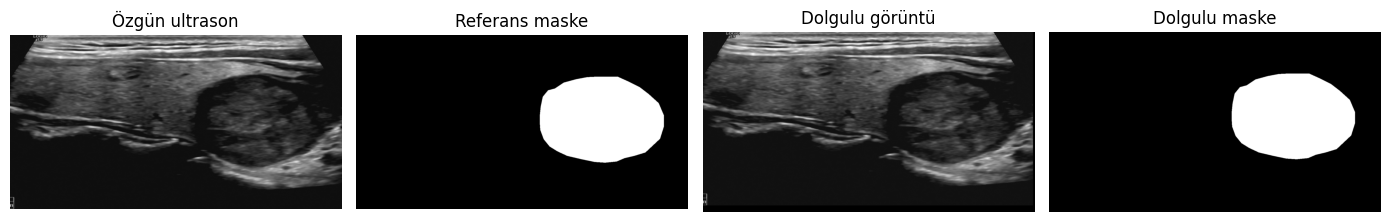

In [33]:
@dataclass(frozen=True)
class Config:
    """Bütün deney seçimleri; EDA ROOT ve SEED değerlerini devralır."""
    root: Path
    seed: int
    output_root: Path = Path.cwd() / 'tn3k_training'
    run_name: str = 'native_unet_image_split_01'
    pad_multiple: int = 32
    fixed_input_hw: tuple[int, int] | None = None  # Alternatif: (832, 1472); resize DEĞİL.
    input_channels: int = 1
    mask_threshold: int = 128
    intensity_scale: float = 255.0
    padding_value: float = 0.0
    foreground_value: float = 1.0
    prediction_threshold: float = 0.5
    validation_fraction: float = 0.20
    normalization: str = 'scale'  # 'scale' veya ayrı ablation için 'zscore'.
    horizontal_flip_probability: float = 0.5
    batch_size: int = 1
    num_workers: int = 0  # Notebook / Windows / Colab için güvenli varsayılan.
    pin_memory: bool = True
    base_channels: int = 16
    depth: int = 4
    norm_groups: int = 4
    conv_kernel: int = 3
    downsample_factor: int = 2
    epochs: int = 100
    learning_rate: float = 1e-3
    weight_decay: float = 1e-4
    gradient_accumulation: int = 4
    gradient_clip: float = 1.0
    loss_kind: str = 'bce_dice'  # Alternatif: 'focal_dice'.
    pixel_loss_weight: float = 0.5
    focal_alpha: float = 0.75
    focal_gamma: float = 2.0
    epsilon: float = 1e-6
    lr_factor: float = 0.5
    lr_patience: int = 5
    min_learning_rate: float = 1e-6
    early_stopping_patience: int = 20
    early_stopping_min_delta: float = 1e-4
    use_amp: bool = True
    activation_checkpointing: bool = True
    deterministic: bool = True
    device: str = 'auto'
    cublas_workspace_config: str = ':4096:8'
    hd_percentile: float = 95.0
    surface_connectivity: int = 1
    small_area_quantile: float = 0.25
    sanity_examples: int = 4
    prediction_examples: int = 4
    overlay_alpha: float = 0.4
    figure_dpi: int = 140

    @property
    def input_shape(self) -> tuple[int, int | None, int | None]:
        """PyTorch C,H,W; None özgün boyuta göre dinamik padding demektir."""
        return (self.input_channels, *(self.fixed_input_hw or (None, None)))

    @property
    def run_dir(self) -> Path:
        return self.output_root / self.run_name

    @property
    def manifest_path(self) -> Path:
        return self.run_dir / 'split_manifest.csv'

    @property
    def best_checkpoint_path(self) -> Path:
        return self.run_dir / 'best.pt'

    @property
    def history_path(self) -> Path:
        return self.run_dir / 'history.csv'

    @property
    def test_dir(self) -> Path:
        return self.run_dir / 'final_test'

    def validate(self) -> None:
        """Gizli resize/fallback yerine geçersiz ayarları açıkça reddet."""
        if not self.root.is_dir():
            raise ValueError(f'EDA ROOT bulunamadı: {self.root}')
        if self.batch_size != 1:
            raise ValueError('Bu değişken boyutlu uygulamada batch_size=1; etkili batch için accumulation kullan.')
        divisor = self.downsample_factor ** self.depth
        if self.downsample_factor != 2 or self.depth < 1 or self.pad_multiple % divisor:
            raise ValueError('pad_multiple, 2**depth ile tam bölünmeli; downsample_factor=2 olmalı.')
        if self.base_channels < self.norm_groups or self.base_channels % self.norm_groups:
            raise ValueError('base_channels norm_groups ile bölünebilmeli.')
        if self.conv_kernel % 2 == 0:
            raise ValueError('Aynı boyutu korumak için tek sayılı convolution kernel gerekli.')
        if self.padding_value != 0.0 or self.foreground_value != 1.0 or self.input_channels != 1:
            raise ValueError('Bu sürüm grayscale giriş, sıfır padding ve {0,1} maske kullanır.')
        if not 0 < self.validation_fraction < 1 or not 0 < self.prediction_threshold < 1:
            raise ValueError('Split ve tahmin eşikleri (0,1) aralığında olmalı.')
        if not 0 <= self.horizontal_flip_probability <= 1 or not 0 <= self.pixel_loss_weight <= 1:
            raise ValueError('Olasılık/ağırlık aralığı [0,1] olmalı.')
        if self.normalization not in ('scale', 'zscore') or self.loss_kind not in ('bce_dice', 'focal_dice'):
            raise ValueError('Bilinmeyen normalizasyon veya loss.')
        if min(self.epochs, self.gradient_accumulation, self.early_stopping_patience) < 1:
            raise ValueError('Epoch, accumulation ve patience pozitif olmalı.')
        if self.fixed_input_hw and any(s <= 0 or s % self.pad_multiple for s in self.fixed_input_hw):
            raise ValueError('Sabit canvas boyutları pozitif pad_multiple katları olmalı.')

def seed_everything(config: Config) -> None:
    """Split, augmentation ve ağırlık başlangıcı için rastgeleliği sabitle."""
    random.seed(config.seed)
    np.random.seed(config.seed)
    torch.manual_seed(config.seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(config.seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = config.deterministic
    torch.use_deterministic_algorithms(config.deterministic)


def select_device(config: Config) -> torch.device:
    """GPU yoksa CPU; istenen CUDA yoksa sessiz fallback yerine hata."""
    name = ('cuda' if torch.cuda.is_available() else 'cpu') if config.device == 'auto' else config.device
    if name.startswith('cuda') and not torch.cuda.is_available():
        raise RuntimeError('CUDA istendi fakat kullanılamıyor.')
    return torch.device(name)


def config_payload(config: Config) -> dict[str, Any]:
    """JSON ve güvenli checkpoint için yalnız ilkel türler üret."""
    return {key: str(value) if isinstance(value, Path) else value for key, value in asdict(config).items()}

def read_image_mask(image_path: str | Path, mask_path: str | Path, config: Config) -> tuple[np.ndarray, np.ndarray]:
    """EDA gibi PIL convert('L') kullan; önce maskeyi ikilileştir, resize yapma."""
    with Image.open(image_path) as image, Image.open(mask_path) as mask:
        if image.size != mask.size:
            raise ValueError(f'Görüntü/maske boyutu farklı: {image_path}')
        x = np.asarray(image.convert('L')).copy()
        y = (np.asarray(mask.convert('L')) >= config.mask_threshold).astype(np.uint8)
    return x, y

@dataclass(frozen=True)
class SpatialInfo:
    """Tahmini özgün koordinata döndürmek için saklanan boyutlar."""
    height: int
    width: int
    padded_height: int
    padded_width: int


def normalize_intensity(image: np.ndarray, config: Config) -> np.ndarray:
    """GT kullanmadan, padding eklenmeden önce yoğunluk ölçekle."""
    result = image.astype(np.float32) / config.intensity_scale
    if config.normalization == 'zscore':
        result = (result - result.mean()) / max(float(result.std()), config.epsilon)
    return result


def pad_without_resampling(image: np.ndarray, mask: np.ndarray, config: Config
                          ) -> tuple[np.ndarray, np.ndarray, np.ndarray, SpatialInfo]:
    """Sağ/alt padding; tüm kaynak pikselleri ve nodül etiketlerini birebir koru."""
    if image.shape != mask.shape or image.ndim != 2:
        raise ValueError('Ön işleme 2D eş boyutlu görüntü/maske bekliyor.')
    if not np.isin(mask, [config.padding_value, config.foreground_value]).all():
        raise ValueError('Maske ikili değil.')
    height, width = image.shape
    multiple = config.pad_multiple
    target_h, target_w = config.fixed_input_hw or (
        math.ceil(height / multiple) * multiple, math.ceil(width / multiple) * multiple)
    if target_h < height or target_w < width:
        raise ValueError('Canvas görüntüden küçük. Resize/crop yasak: canvas büyüt veya dinamik kullan.')
    padding = ((0, target_h - height), (0, target_w - width))
    padded_image = np.pad(image, padding, constant_values=config.padding_value)
    padded_mask = np.pad(mask, padding, constant_values=config.padding_value)
    valid = np.pad(np.ones(mask.shape, np.float32), padding, constant_values=config.padding_value)
    if not np.array_equal(padded_image[:height, :width], image):
        raise AssertionError('Görüntü pikselleri değişti.')
    if not np.array_equal(padded_mask[:height, :width], mask) or padded_mask.sum() != mask.sum():
        raise AssertionError('Maske pikselleri kayboldu veya yer değiştirdi.')
    return padded_image, padded_mask, valid, SpatialInfo(height, width, target_h, target_w)


def preprocess_native_pair(image_path: str | Path, mask_path: str | Path, config: Config,
                           augment: bool = False) -> tuple[np.ndarray, np.ndarray, np.ndarray, SpatialInfo]:
    """EDA preprocess_pair örneğinden ayrı, eğitimde kullanılan kayıpsız geometri."""
    image, mask = read_image_mask(image_path, mask_path, config)
    if augment and random.random() < config.horizontal_flip_probability:
        image, mask = np.fliplr(image).copy(), np.fliplr(mask).copy()
    return pad_without_resampling(normalize_intensity(image, config), mask, config)

class ThyroidNoduleDataset(Dataset):
    """EDA yollarını kullanır; yalnız train için ortak yatay flip uygular."""
    def __init__(self, table: pd.DataFrame, config: Config, augment: bool = False) -> None:
        self.table = table.reset_index(drop=True).copy()
        self.config = config
        self.augment = augment

    def __len__(self) -> int:
        return len(self.table)

    def __getitem__(self, index: int) -> dict[str, Any]:
        row = self.table.iloc[index]
        image, mask, valid, info = preprocess_native_pair(row.image_path, row.mask_path, self.config, self.augment)
        tensors = {name: torch.from_numpy(np.ascontiguousarray(array[None], dtype=np.float32))
                   for name, array in [('image', image), ('mask', mask), ('valid', valid)]}
        return {**tensors, 'height': info.height, 'width': info.width, 'index': index}


def seed_worker(worker_id: int) -> None:
    """DataLoader alt süreçlerinin Python/NumPy RNG durumlarını sabitle."""
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def make_loader(table: pd.DataFrame, config: Config, training: bool = False) -> DataLoader:
    """Bir batch bir görüntü; farklı boyutları stack etme ihtiyacı yok."""
    generator = torch.Generator().manual_seed(config.seed)
    return DataLoader(ThyroidNoduleDataset(table, config, augment=training), batch_size=config.batch_size,
                      shuffle=training, num_workers=config.num_workers, worker_init_fn=seed_worker,
                      generator=generator, pin_memory=config.pin_memory and select_device(config).type == 'cuda')


cfg = Config(root=data_root, output_root=run_dir.parent, run_name=EXPERIMENT_NAME,
             seed=42, epochs=TOTAL_EPOCHS, device="cuda")
cfg.validate()
branch_channels = 8

# Yalnız eğitim yükleyicisi görüntü ve maskeyi birlikte yatay çevirir.
example = train_table.assign(
    padded_pixels=((train_table["height"] + 31) // 32 * 32)
    * ((train_table["width"] + 31) // 32 * 32)
).sort_values("padded_pixels", ascending=False).iloc[0]
original_image, original_mask = read_image_mask(example.image_path, example.mask_path, cfg)
padded_image, padded_mask, valid, info = preprocess_native_pair(example.image_path, example.mask_path, cfg)
print(f"{example.filename} · özgün: {original_image.shape} · dolgulu: {padded_image.shape}")
assert int(valid.sum()) == original_image.size
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for axis, pixels, label in zip(axes, (original_image, original_mask, padded_image, padded_mask),
                              ("Özgün ultrason", "Referans maske", "Dolgulu görüntü", "Dolgulu maske")):
    axis.imshow(pixels, cmap="gray")
    axis.set_title(label)
    axis.axis("off")
fig.tight_layout()
plt.show()

## 4 · Mimari ve kısa GPU denemesi

Kaynak U-Net 3+ mimarisini ayrı bir modelle kurar. En büyük dolgulu eğitim örneğinde ileri geçişi, kaybı ve geri yayılımı kontrol eder.

In [34]:
class DoubleConvolution(nn.Module):
    """Same-padding convolution + GroupNorm: batch=1 için kararlı blok."""
    def __init__(self, in_channels: int, out_channels: int, config: Config) -> None:
        super().__init__()
        padding = config.conv_kernel // 2
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, config.conv_kernel, padding=padding, bias=False),
            nn.GroupNorm(config.norm_groups, out_channels), nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, config.conv_kernel, padding=padding, bias=False),
            nn.GroupNorm(config.norm_groups, out_channels), nn.ReLU())

    def forward(self, tensor: torch.Tensor) -> torch.Tensor:
        return self.layers(tensor)

class NativeResolutionUNet3Plus(nn.Module):
    """Full-scale skip bağlantıları olan, tek çıkışlı 2D U-Net 3+."""

    def __init__(self, config, branch_channels: int = 8):
        super().__init__()
        self.config = config
        self.depth = config.depth

        if branch_channels % config.norm_groups != 0:
            raise ValueError("branch_channels, norm_groups ile tam bölünmeli.")

        encoder_widths = [
            config.base_channels * 2**level
            for level in range(self.depth + 1)
        ]
        fusion_width = (self.depth + 1) * branch_channels

        self.encoder = nn.ModuleList([
            DoubleConvolution(in_channels, out_channels, config)
            for in_channels, out_channels in zip(
                [config.input_channels] + encoder_widths[:-1],
                encoder_widths,
            )
        ])

        self.projections = nn.ModuleDict()
        self.fusions = nn.ModuleDict()

        for level in reversed(range(self.depth)):
            source_widths = (
                encoder_widths[:level + 1]
                + [fusion_width] * (self.depth - level - 1)
                + [encoder_widths[-1]]
            )

            self.projections[str(level)] = nn.ModuleList([
                nn.Sequential(
                    nn.Conv2d(
                        width, branch_channels, kernel_size=3,
                        padding=1, bias=False,
                    ),
                    nn.GroupNorm(config.norm_groups, branch_channels),
                    nn.ReLU(),
                )
                for width in source_widths
            ])

            self.fusions[str(level)] = DoubleConvolution(
                fusion_width, fusion_width, config
            )

        self.output = nn.Conv2d(fusion_width, 1, kernel_size=1)

    def _apply_block(self, block, x):
        if self.training and self.config.activation_checkpointing:
            return checkpoint(block, x, use_reentrant=False)
        return block(x)

    @staticmethod
    def _match_size(x, target_hw):
        """Özellik haritasını hedef decoder seviyesinin boyutuna getir."""
        height, width = x.shape[-2:]
        target_height, target_width = target_hw

        if (height, width) == (target_height, target_width):
            return x

        # Küçültme: birbirine taşmayan, sabit pencereli max pooling.
        if height >= target_height and width >= target_width:
            if height % target_height == 0 and width % target_width == 0:
                factor = (height // target_height, width // target_width)
                return F.max_pool2d(x, kernel_size=factor, stride=factor)

        # Büyütme: her özellik değerini tam sayı katsayısıyla tekrarla.
        if height <= target_height and width <= target_width:
            if target_height % height == 0 and target_width % width == 0:
                scale_h = target_height // height
                scale_w = target_width // width
                batch, channels = x.shape[:2]

                return (
                    x.reshape(batch, channels, height, 1, width, 1)
                    .expand(batch, channels, height, scale_h, width, scale_w)
                    .reshape(batch, channels, target_height, target_width)
                )

        raise ValueError(
            f"Özellik haritası boyutları tam kat olmalı. "
            f"Kaynak {(height, width)}, hedef {(target_height, target_width)}."
        )

    def forward(self, x):
        divisor = 2**self.depth
        if any(size % divisor != 0 for size in x.shape[-2:]):
            raise ValueError(
                f"Girdi yüksekliği ve genişliği {divisor} katı olmalı."
            )

        encoder_features = []
        for level, block in enumerate(self.encoder):
            if level > 0:
                x = F.max_pool2d(x, kernel_size=2, stride=2)
            x = self._apply_block(block, x)
            encoder_features.append(x)

        decoder_features = {}
        for level in reversed(range(self.depth)):
            target_hw = encoder_features[level].shape[-2:]
            sources = (
                encoder_features[:level + 1]
                + [
                    decoder_features[k]
                    for k in range(level + 1, self.depth)
                ]
                + [encoder_features[-1]]
            )

            projected = [
                self._apply_block(
                    projection, self._match_size(feature, target_hw)
                )
                for projection, feature in zip(
                    self.projections[str(level)], sources
                )
            ]

            decoder_features[level] = self._apply_block(
                self.fusions[str(level)], torch.cat(projected, dim=1)
            )

        return self.output(decoder_features[0])

class MaskedSegmentationLoss(nn.Module):
    """Gerçek piksel alanında BCE/Focal + soft Dice; padding'e loss verme."""
    def __init__(self, config: Config) -> None:
        super().__init__()
        self.config = config

    def forward(self, logits: torch.Tensor, target: torch.Tensor, valid: torch.Tensor) -> torch.Tensor:
        logits, target, valid = logits.float(), target.float(), valid.float()
        probability = logits.sigmoid()
        pixel_loss = F.binary_cross_entropy_with_logits(logits, target, reduction='none')
        if self.config.loss_kind == 'focal_dice':
            probability_true = probability * target + (1 - probability) * (1 - target)
            alpha = self.config.focal_alpha * target + (1 - self.config.focal_alpha) * (1 - target)
            pixel_loss = alpha * (1 - probability_true).pow(self.config.focal_gamma) * pixel_loss
        axes = (1, 2, 3)
        pixel_loss = (pixel_loss * valid).sum(axes) / valid.sum(axes).clamp_min(self.config.epsilon)
        intersection = (probability * target * valid).sum(axes)
        denominator = (probability * valid).sum(axes) + (target * valid).sum(axes)
        dice_loss = 1 - (2 * intersection + self.config.epsilon) / (denominator + self.config.epsilon)
        weight = self.config.pixel_loss_weight
        return (weight * pixel_loss + (1 - weight) * dice_loss).mean()


def overlap_scores(prediction: np.ndarray, target: np.ndarray) -> dict[str, float | bool]:
    """Tek görüntü Dice/IoU; boş maske politikasını açık tanımla."""
    prediction, target = prediction.astype(bool), target.astype(bool)
    intersection = np.logical_and(prediction, target).sum()
    denominator = prediction.sum() + target.sum()
    union = np.logical_or(prediction, target).sum()
    return {'dice': float(2 * intersection / denominator) if denominator else 1.0,
            'iou': float(intersection / union) if union else 1.0,
            'empty_prediction': bool(not prediction.any()), 'empty_target': bool(not target.any())}


def surface_hd95(prediction: np.ndarray, target: np.ndarray, config: Config) -> float:
    """İki yönlü yüzey uzaklığı p95 maksimumu, özgün piksel birimi."""
    prediction, target = prediction.astype(bool), target.astype(bool)
    if not prediction.any() and not target.any():
        return 0.0
    if not prediction.any() or not target.any():
        return float('inf')
    structure = ndi.generate_binary_structure(2, config.surface_connectivity)
    prediction_surface = prediction ^ ndi.binary_erosion(prediction, structure=structure, border_value=0)
    target_surface = target ^ ndi.binary_erosion(target, structure=structure, border_value=0)
    to_target = ndi.distance_transform_edt(~target_surface)[prediction_surface]
    to_prediction = ndi.distance_transform_edt(~prediction_surface)[target_surface]
    return float(max(np.percentile(to_target, config.hd_percentile), np.percentile(to_prediction, config.hd_percentile)))


def scores_from_logits(logits: torch.Tensor, batch: dict[str, Any], config: Config, include_hd: bool = False
                      ) -> tuple[dict[str, Any], np.ndarray]:
    """Yalnız yapay padding'i kaldır; görüntünün özgün alanında metrik hesapla."""
    height, width = int(batch['height'].item()), int(batch['width'].item())
    prediction = (logits.detach().float().sigmoid()[0, 0, :height, :width].cpu().numpy() >= config.prediction_threshold)
    target = batch['mask'][0, 0, :height, :width].cpu().numpy().astype(bool)
    scores = overlap_scores(prediction, target)
    if include_hd:
        scores['hd95_px'] = surface_hd95(prediction, target, config)
    return scores, prediction

def run_training_epoch(model: nn.Module, data_loader: DataLoader, criterion: nn.Module,
                       optimizer: torch.optim.Optimizer, scaler: Any, device: torch.device,
                       config: Config) -> dict[str, float]:
    """Bir epoch; son eksik accumulation grubunu doğru ağırlıkla güncelle."""
    model.train()
    optimizer.zero_grad(set_to_none=True)
    records = []
    amp_enabled = config.use_amp and device.type == 'cuda'
    for step, batch in enumerate(data_loader):
        image, target, valid = [batch[key].to(device) for key in ('image', 'mask', 'valid')]
        group_start = (step // config.gradient_accumulation) * config.gradient_accumulation
        group_size = min(config.gradient_accumulation, len(data_loader) - group_start)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp_enabled):
            logits = model(image)
            loss = criterion(logits, target, valid)
        if not torch.isfinite(loss):
            raise FloatingPointError('Training loss NaN/inf; eğitim durduruldu.')
        scaler.scale(loss / group_size).backward()
        if (step + 1) % config.gradient_accumulation == 0 or step + 1 == len(data_loader):
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), config.gradient_clip)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
        scores, _ = scores_from_logits(logits, batch, config)
        records.append({'loss': loss.item(), 'dice': scores['dice'], 'iou': scores['iou']})
    return pd.DataFrame(records).mean().to_dict()


@torch.no_grad()
def evaluate_loader(model: nn.Module, data_loader: DataLoader, criterion: nn.Module,
                    device: torch.device, config: Config, include_hd: bool = False,
                    prediction_dir: Path | None = None) -> pd.DataFrame:
    """Augmentation'sız validation/test; özgün boyutta PNG ve görüntü bazlı skorlar."""
    model.eval()
    records = []
    loader = data_loader.iterable if isinstance(data_loader, tqdm) else data_loader
    if prediction_dir:
        prediction_dir.mkdir(parents=True, exist_ok=True)
    for batch in data_loader:
        image, target, valid = [batch[key].to(device) for key in ('image', 'mask', 'valid')]
        with torch.autocast(device_type=device.type, dtype=torch.float16,
                            enabled=config.use_amp and device.type == 'cuda'):
            logits = model(image)
            loss = criterion(logits, target, valid)
        if not torch.isfinite(loss):
            raise FloatingPointError('Değerlendirme loss NaN/inf.')
        scores, prediction = scores_from_logits(logits, batch, config, include_hd)
        row = loader.dataset.table.iloc[int(batch['index'].item())]
        records.append({'split': row['split'], 'filename': row.filename, 'image_hash': str(row.image_hash),
                        'foreground_pixels': int(row.foreground_pixels), 'loss': loss.item(), **scores})
        if prediction_dir:
            name = row['split'] + '_' + Path(row.filename).stem + '.png'
            Image.fromarray(prediction.astype(np.uint8) * int(config.intensity_scale)).save(prediction_dir / name)
    return pd.DataFrame(records)


def rng_state():
    name, keys, position, has_gauss, cached_gauss = np.random.get_state()
    return {"python": random.getstate(),
            "numpy": (name, keys.tolist(), position, has_gauss, cached_gauss),
            "cpu": torch.get_rng_state(), "cuda": torch.cuda.get_rng_state_all()}


def restore_rng(saved):
    random.setstate(saved["python"])
    name, keys, position, has_gauss, cached_gauss = saved["numpy"]
    np.random.set_state((name, np.asarray(keys, dtype=np.uint32), position, has_gauss, cached_gauss))
    torch.set_rng_state(saved["cpu"])
    torch.cuda.set_rng_state_all(saved["cuda"])


def smoke_test():
    saved = rng_state()
    phase = "CUDA modelini ve girdileri hazırlama"
    try:
        torch.cuda.reset_peak_memory_stats(device)
        probe = NativeResolutionUNet3Plus(cfg, branch_channels).to(device).train()
        row = example.to_frame().T
        batch = next(iter(make_loader(row, cfg)))
        image, target, valid = (batch[key].to(device) for key in ("image", "mask", "valid"))
        assert next(probe.parameters()).is_cuda and all(x.is_cuda for x in (image, target, valid))
        phase = "ileri geçiş"
        with torch.autocast("cuda", dtype=torch.float16, enabled=cfg.use_amp):
            logits = probe(image)
            phase = "kayıp hesabı"
            loss = MaskedSegmentationLoss(cfg)(logits, target, valid)
        if logits.shape != target.shape or not torch.isfinite(loss):
            raise RuntimeError(f"Geçersiz çıktı/kayıp: {logits.shape}, {target.shape}, {loss.item()}")
        phase = "AMP geri yayılımı"
        probe_scaler = torch.amp.GradScaler("cuda", enabled=cfg.use_amp)
        probe_scaler.scale(loss).backward()
        torch.cuda.synchronize(device)
        peak = torch.cuda.max_memory_allocated(device) / 1024**3
        total = torch.cuda.get_device_properties(device).total_memory / 1024**3
        print(f"Model ve tensörler CUDA'da | Girdi: {tuple(image.shape)} | Çıktı: {tuple(logits.shape)}")
        print(f"Kayıp: {loss.item():.5f} | Tepe ayrılan GPU belleği: {peak:.2f} / {total:.2f} GiB")
    except torch.cuda.OutOfMemoryError as error:
        raise RuntimeError(f"T4 belleği yetersiz. İşlem: {phase} | örnek: {example.filename}") from error
    finally:
        restore_rng(saved)


smoke_test()
torch.cuda.empty_cache()

Model ve tensörler CUDA'da | Girdi: (1, 1, 800, 1472) | Çıktı: (1, 1, 800, 1472)
Kayıp: 0.68812 | Tepe ayrılan GPU belleği: 4.46 / 14.56 GiB


## 5 · Deneyi aç ve devam kaydını doğrula

Ayarları ve veri kimliğini kontrol eder. Okunabilir son kaydı yükler, gerekirse önceki sağlam kayda döner ve geçmişi bu kayıttan yeniden oluşturur.

In [35]:
cfg_identity = config_payload(cfg)
# Aynı veri başka bir oturumda farklı yerel dizine inebilir.
del cfg_identity["root"], cfg_identity["output_root"]
spec = {
    "format_version": 1, "architecture": "UNet3Plus_no_deep_supervision",
    "branch_channels": branch_channels, "config": cfg_identity,
    "split_hash": manifest_sha256, "dataset_source": dataset_source,
}
spec = json.loads(json.dumps(spec))
run_dir.mkdir(parents=True, exist_ok=True)
settings_path = run_dir / "experiment.json"
manifest_backup = run_dir / "verified_split_manifest.csv"
last_path = run_dir / "last_unet3plus.pt"
previous_path = run_dir / "previous_unet3plus.pt"
best_path = run_dir / "best_unet3plus.pt"
history_path = run_dir / "history_unet3plus.csv"
finished_path = run_dir / "training_completed.json"


def write_bytes(path, content):
    pending = path.with_name(path.name + ".tmp")
    pending.write_bytes(content)
    if pending.read_bytes() != content:
        raise IOError(f"Drive dosyası doğrulanamadı: {pending}")
    pending.replace(path)


def save_settings():
    write_bytes(settings_path, json.dumps(spec, ensure_ascii=False, indent=2).encode("utf-8"))


def validate_record(record, path):
    required = {"spec", "epoch", "rows", "best", "patience_dice", "stale_epochs",
                "model_state", "optimizer_state", "scheduler_state", "scaler_state",
                "rng", "train_generator", "val_generator"}
    if not isinstance(record, dict) or not required.issubset(record):
        raise ValueError(f"Eksik devam kaydı alanları: {path}")
    if record["spec"] != spec:
        raise ValueError(f"Deney ayarları veya manifest kayıtla farklı: {path}")
    epochs = [row["epoch"] for row in record["rows"]]
    if not 1 <= record["epoch"] <= cfg.epochs or epochs != list(range(1, record["epoch"] + 1)):
        raise ValueError(f"Checkpoint epoch geçmişi geçersiz: {path}")
    best = record["best"]
    winner = max(record["rows"], key=lambda row: row["val_dice"])
    if (best["spec"] != spec or best["epoch"] != winner["epoch"]
            or best["best_val_dice"] != winner["val_dice"]):
        raise ValueError(f"En iyi ağırlığın bilgisi kayıtla uyumsuz: {path}")


def read_record(path):
    record = torch.load(path, map_location="cpu", weights_only=True)
    validate_record(record, path)
    return record


def save_torch(path, payload, check):
    pending = path.with_name(path.name + ".tmp")
    torch.save(payload, pending)
    check(pending)
    pending.replace(path)
    check(path)


def check_best(path, selected):
    candidate = torch.load(path, map_location="cpu", weights_only=True)
    if (candidate["spec"] != spec or candidate["epoch"] != selected["epoch"]
            or candidate["best_val_dice"] != selected["best_val_dice"]
            or candidate["model_state"].keys() != selected["model_state"].keys()
            or any(not torch.equal(candidate["model_state"][key], value)
                   for key, value in selected["model_state"].items())):
        raise ValueError(f"Seçilen ağırlık doğrulanamadı: {path}")


def sync_outputs(record):
    selected = record["best"]
    try:
        check_best(best_path, selected)
    except Exception:
        save_torch(best_path, selected, lambda path: check_best(path, selected))
    history = pd.DataFrame(record["rows"]).to_csv(index=False)
    write_bytes(history_path, history.encode("utf-8"))
    stop = terminal_reason(record)
    if stop:
        completed = {"last_epoch": record["epoch"], "best_epoch": selected["epoch"],
                     "best_val_dice": selected["best_val_dice"], "reason": stop,
                     "manifest_sha256": manifest_sha256}
        write_bytes(finished_path, json.dumps(completed, ensure_ascii=False, indent=2).encode("utf-8"))
    elif finished_path.exists():
        finished_path.unlink()


def terminal_reason(record):
    if record["stale_epochs"] >= cfg.early_stopping_patience:
        return "Erken durdurma"
    if record["epoch"] >= cfg.epochs:
        return "Deneyin toplam epoch sınırına ulaşıldı"
    return None


record = None
loaded_path = None
if settings_path.is_file():
    if json.loads(settings_path.read_text(encoding="utf-8")) != spec:
        raise ValueError(f"Ayarlar {settings_path} ile uyuşmuyor. Aynı deney için ilk ayarları kullan.")
elif any(run_dir.iterdir()):
    raise RuntimeError(f"Deney klasöründe dosyalar var ama experiment.json yok: {run_dir}")
else:
    save_settings()

if manifest_backup.exists():
    if hashlib.sha256(manifest_backup.read_bytes()).hexdigest() != manifest_sha256:
        raise ValueError(f"Deneyin manifest kopyası uyuşmuyor: {manifest_backup}")
else:
    write_bytes(manifest_backup, manifest_bytes)

pending_last = last_path.with_name(last_path.name + ".tmp")
for candidate in (last_path, previous_path, pending_last):
    if not candidate.exists():
        continue
    try:
        record = read_record(candidate)
    except Exception as error:
        print(f"Devam kaydı kullanılamadı: {candidate} | {type(error).__name__}: {error}")
        continue
    if candidate == pending_last:
        print(f"Son kayıt yayımlanmadan kesilmiş. Doğrulanmış geçici kayıt kurtarılıyor: {candidate}")
        pending_last.replace(last_path)
        record = read_record(last_path)
        candidate = last_path
    loaded_path = candidate
    break

training_files = (last_path, previous_path, best_path, history_path, finished_path,
                  last_path.with_name(last_path.name + ".tmp"),
                  previous_path.with_name(previous_path.name + ".tmp"))
if record is None and any(path.exists() for path in training_files):
    raise RuntimeError(f"Sağlam devam kaydı bulunamadı: {run_dir}. Bu deney otomatik olarak sıfırlanmadı.")

seed_everything(cfg)
model = NativeResolutionUNet3Plus(cfg, branch_channels).to(device)
criterion = MaskedSegmentationLoss(cfg)
optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.learning_rate, weight_decay=cfg.weight_decay)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=cfg.lr_factor, patience=cfg.lr_patience, min_lr=cfg.min_learning_rate
)
scaler = torch.amp.GradScaler("cuda", enabled=cfg.use_amp)
train_loader = make_loader(train_table, cfg, training=True)
val_loader = make_loader(val_table, cfg)

if record is not None:
    model.load_state_dict(record["model_state"], strict=True)
    optimizer.load_state_dict(record["optimizer_state"])
    scheduler.load_state_dict(record["scheduler_state"])
    scaler.load_state_dict(record["scaler_state"])
    train_loader.generator.set_state(record["train_generator"])
    val_loader.generator.set_state(record["val_generator"])
    restore_rng(record["rng"])
    sync_outputs(record)
    completed_epoch = record["epoch"]
    print("Yüklenen kayıt:", loaded_path)
else:
    completed_epoch = 0
    print("Yeni deney. Model ağırlıkları rastgele başlatıldı.")

if record is not None and terminal_reason(record):
    print(f"Son tamamlanan epoch: {completed_epoch} / Deney tamamlandı.")
else:
    print(f"Son tamamlanan epoch: {completed_epoch} / Başlanacak epoch: {completed_epoch + 1}")

Yüklenen kayıt: /content/drive/MyDrive/TN3K/UNet3/Colab_T4_Sifirdan_01/last_unet3plus.pt
Son tamamlanan epoch: 21 / Başlanacak epoch: 22


## 6 · Eğitim ve doğrulama

Bu oturum için seçilen sayıda tam epoch çalıştırır. Her epoch sonunda yeni kayıt doğrulanır ve mümkünse önceki sağlam kayıt korunur.

In [36]:
def persist_epoch(payload, prior_path):
    if prior_path == last_path:
        # Sağlam last kaydını koru. Bu adım bitmeden last dosyasına dokunma.
        pending = previous_path.with_name(previous_path.name + ".tmp")
        shutil.copyfile(last_path, pending)
        read_record(pending)
        pending.replace(previous_path)
        read_record(previous_path)
    # fallback previous olduysa onu olduğu gibi koru.
    save_torch(last_path, payload, read_record)


stop_reason = terminal_reason(record) if record else None
rows = list(record["rows"]) if record else []
best = record["best"] if record else None
patience_dice = record["patience_dice"] if record else -math.inf
stale_epochs = record["stale_epochs"] if record else 0
small_area_cutoff = float(train_table["foreground_pixels"].quantile(cfg.small_area_quantile))
session_end = min(cfg.epochs, completed_epoch + EPOCHS_THIS_SESSION)

if not stop_reason:
    for epoch in range(completed_epoch + 1, session_end + 1):
        started = perf_counter()
        print(f"Epoch {epoch} başladı | {len(train_table)} eğitim / {len(val_table)} doğrulama")
        with tqdm(train_loader, desc=f"Epoch {epoch} · eğitim", unit="görüntü") as bar:
            training = run_training_epoch(model, bar, criterion, optimizer, scaler, device, cfg)
        training_seconds = perf_counter() - started
        with tqdm(val_loader, desc=f"Epoch {epoch} · doğrulama", unit="görüntü") as bar:
            validation = evaluate_loader(model, bar, criterion, device, cfg)
        if len(validation) != len(val_table):
            raise RuntimeError(f"Doğrulama eksik: {len(validation)}/{len(val_table)}.")
        val_scores = validation[["loss", "dice", "iou"]].mean().to_dict()
        score = float(val_scores["dice"])
        if not math.isfinite(score):
            raise ValueError(f"Epoch {epoch}: doğrulama Dice sonlu değil.")

        scheduler.step(score)
        if best is None or score > best["best_val_dice"]:
            best = {"spec": spec, "epoch": epoch, "best_val_dice": score,
                    "small_area_cutoff": small_area_cutoff,
                    "model_state": {key: value.detach().cpu().clone()
                                    for key, value in model.state_dict().items()}}
        if score > patience_dice + cfg.early_stopping_min_delta:
            patience_dice, stale_epochs = score, 0
        else:
            stale_epochs += 1

        rows.append({
            "epoch": epoch,
            **{f"train_{key}": value for key, value in training.items()},
            **{f"val_{key}": value for key, value in val_scores.items()},
            "learning_rate": optimizer.param_groups[0]["lr"],
            "train_seconds": training_seconds, "val_seconds": perf_counter() - started - training_seconds,
            "epoch_seconds": perf_counter() - started,
        })
        record = {
            "spec": spec, "epoch": epoch, "rows": rows, "best": best,
            "patience_dice": patience_dice, "stale_epochs": stale_epochs,
            "model_state": model.state_dict(), "optimizer_state": optimizer.state_dict(),
            "scheduler_state": scheduler.state_dict(), "scaler_state": scaler.state_dict(),
            "rng": rng_state(), "train_generator": train_loader.generator.get_state(),
            "val_generator": val_loader.generator.get_state(),
        }
        persist_epoch(record, loaded_path)
        loaded_path = last_path
        sync_outputs(record)
        print(f"Epoch {epoch} kaydedildi | val Dice: {score:.4f} | val IoU: {val_scores['iou']:.4f} | "
              f"eğitim: {rows[-1]['train_seconds']:.0f} sn | doğrulama: {rows[-1]['val_seconds']:.0f} sn")
        print(last_path)
        stop_reason = terminal_reason(record)
        if stop_reason:
            break

stop_reason = stop_reason or "Oturum epoch sınırına ulaşıldı. Deney devam edebilir."

Epoch 22 başladı | 2303 eğitim / 576 doğrulama


Epoch 22 · eğitim:   0%|          | 0/2303 [00:00<?, ?görüntü/s]

Epoch 22 · doğrulama:   0%|          | 0/576 [00:00<?, ?görüntü/s]

Epoch 22 kaydedildi | val Dice: 0.7472 | val IoU: 0.6308 | eğitim: 320 sn | doğrulama: 25 sn
/content/drive/MyDrive/TN3K/UNet3/Colab_T4_Sifirdan_01/last_unet3plus.pt
Epoch 23 başladı | 2303 eğitim / 576 doğrulama


Epoch 23 · eğitim:   0%|          | 0/2303 [00:00<?, ?görüntü/s]

Epoch 23 · doğrulama:   0%|          | 0/576 [00:00<?, ?görüntü/s]

... (174 outputs left out)

Epoch 81 kaydedildi | val Dice: 0.7798 | val IoU: 0.6739 | eğitim: 317 sn | doğrulama: 25 sn
/content/drive/MyDrive/TN3K/UNet3/Colab_T4_Sifirdan_01/last_unet3plus.pt
Epoch 82 başladı | 2303 eğitim / 576 doğrulama


Epoch 82 · eğitim:   0%|          | 0/2303 [00:00<?, ?görüntü/s]

Epoch 82 · doğrulama:   0%|          | 0/576 [00:00<?, ?görüntü/s]

Epoch 82 kaydedildi | val Dice: 0.7788 | val IoU: 0.6731 | eğitim: 314 sn | doğrulama: 25 sn
/content/drive/MyDrive/TN3K/UNet3/Colab_T4_Sifirdan_01/last_unet3plus.pt


## 7 · Eğitim özeti

Drive’daki kayıtlı geçmişten eğrileri çizer. Bir sonraki aşamadaki final test için seçilen ağırlığı ve ortak veri kimliğini gösterir.

Tamamlanan epoch: 82
Durma nedeni: Erken durdurma
En iyi doğrulama Dice: 79.0378% | Epoch: 62
Devam kaydı: /content/drive/MyDrive/TN3K/UNet3/Colab_T4_Sifirdan_01/last_unet3plus.pt
Final testte kullanılacak ağırlık: /content/drive/MyDrive/TN3K/UNet3/Colab_T4_Sifirdan_01/best_unet3plus.pt
Base U-Net ile ortak manifest SHA-256: 8e7f07f36625f59bd0f233e8c4f84ecc4e0f181fbad77788c6513f1d4df6867b


,epoch,train_loss,train_dice,train_iou,val_loss,val_dice,val_iou,learning_rate,train_seconds,val_seconds,epoch_seconds
77,78,0.060260,0.932731,0.877247,0.214587,0.782784,0.676969,0.000125,311.490930,24.252840,335.743770
78,79,0.060496,0.932556,0.877196,0.215822,0.781149,0.675804,0.000125,310.200550,24.340462,334.541013
79,80,0.059041,0.934112,0.879855,0.220646,0.780439,0.674835,0.000063,314.379679,24.744308,339.123987
80,81,0.057569,0.935736,0.882553,0.220346,0.779838,0.673945,0.000063,316.583567,24.766204,341.349772
81,82,0.057526,0.935711,0.882775,0.222907,0.778818,0.673144,0.000063,314.442083,24.787655,339.229739


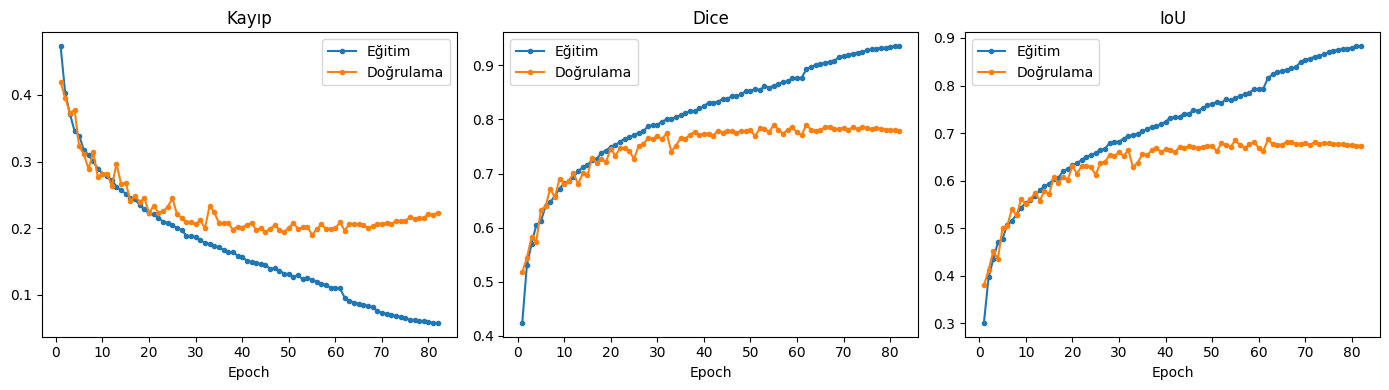

In [37]:
history = pd.read_csv(history_path)
print("Tamamlanan epoch:", len(history))
print("Durma nedeni:", stop_reason)
print(f"En iyi doğrulama Dice: {record['best']['best_val_dice']:.4%} | Epoch: {record['best']['epoch']}")
print("Devam kaydı:", loaded_path)
print("Final testte kullanılacak ağırlık:", best_path)
print("Base U-Net ile ortak manifest SHA-256:", manifest_sha256)
display(history.tail())
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for axis, metric in zip(axes, ("loss", "dice", "iou")):
    axis.plot(history["epoch"], history[f"train_{metric}"], marker=".", label="Eğitim")
    axis.plot(history["epoch"], history[f"val_{metric}"], marker=".", label="Doğrulama")
    axis.set(xlabel="Epoch", title={"loss": "Kayıp", "dice": "Dice", "iou": "IoU"}[metric])
    axis.legend()
fig.tight_layout()
fig.savefig(run_dir / "training_curves.png", dpi=cfg.figure_dpi)
plt.show()